## 01 — Setup and Shared Storage

In [1]:
from pathlib import Path
import os, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
SEED = 42
# Optional shared storage: mount Drive for persistent files across Colab notebooks.
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    ROOT = Path('/content/drive/MyDrive/CAI470_Project')
else:
    ROOT = Path.cwd() / 'CAI470_Project'
RAW = ROOT / 'raw'
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
for p in [RAW, OUT, FIG]: p.mkdir(parents=True, exist_ok=True)
print('Shared project folder:', ROOT)

Mounted at /content/drive
Shared project folder: /content/drive/MyDrive/CAI470_Project


## 02 — Load Official UNSW-NB15 Splits

In [5]:
TRAIN_NAME = 'UNSW_NB15_training-set.csv'
TEST_NAME = 'UNSW_NB15_testing-set.csv'
BASE_URL = 'https://raw.githubusercontent.com/jamshaid120/UNSW_NB15-Complete-dataset/main/'
# Mirror of the official fixed UNSW-NB15 train/test partition.
# If downloading is blocked, upload the two ORIGINAL CSV files from UNSW here.
for name in [TRAIN_NAME, TEST_NAME]:
    path = RAW / name
    if not path.is_file():
        try:
            print('Downloading:', name)
            import requests
            response = requests.get(BASE_URL + name, timeout=120)
            response.raise_for_status()
            path.write_bytes(response.content)
        except Exception as e:
            print('Automatic download unavailable:', type(e).__name__)
            if 'google.colab' in sys.modules:
                from google.colab import files as colab_files
                print('Upload ORIGINAL:', name)
                uploaded = colab_files.upload()
                match = next((v for k,v in uploaded.items() if Path(k).name.lower()==name.lower()), None)
                if match is None:
                    raise FileNotFoundError(f'Please upload {name}; provided files: {list(uploaded)}')
                path.write_bytes(match)
            else:
                raise FileNotFoundError(f'Download or place {name} into {RAW}') from e
    if path.stat().st_size < 1_000_000:
        raise ValueError(f'{name} is unexpectedly small; check the source CSV.')
train = pd.read_csv(RAW/TRAIN_NAME, low_memory=False)
test = pd.read_csv(RAW/TEST_NAME, low_memory=False)
train.columns = train.columns.str.strip()
test.columns = test.columns.str.strip()
assert len(train) == 175341 and len(test) == 82332, (train.shape, test.shape)
assert list(train.columns) == list(test.columns), 'Train/test columns do not match.'
assert {'id','attack_cat','label'}.issubset(train.columns)
assert set(pd.to_numeric(train.label).unique()) <= {0,1}
assert set(pd.to_numeric(test.label).unique()) <= {0,1}
print('Training:', train.shape, 'Testing:', test.shape)

Training: (175341, 45) Testing: (82332, 45)


## 03 — Dataset Overview

In [6]:
display(train.head(5)); display(pd.DataFrame({'train_dtype':train.dtypes.astype(str),'missing_train':train.isna().sum(),'missing_test':test.isna().sum()}))
print('Target counts (Train):');print(train['label'].value_counts().sort_index())
print('Target counts (Test):');print(test['label'].value_counts().sort_index())

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


,train_dtype,missing_train,missing_test
id,int64,0,0
dur,float64,0,0
proto,object,0,0
service,object,0,0
state,object,0,0
spkts,int64,0,0
dpkts,int64,0,0
sbytes,int64,0,0
dbytes,int64,0,0
rate,float64,0,0


Target counts (Train):
label
0     56000
1    119341
Name: count, dtype: int64
Target counts (Test):
label
0    37000
1    45332
Name: count, dtype: int64


## 04 — Identify Features and Labels

In [7]:
TARGET = 'label'
EXCLUDE = ['id', 'attack_cat', TARGET]
FEATURES = [c for c in train.columns if c not in EXCLUDE]
CAT = [c for c in ['proto', 'service', 'state'] if c in FEATURES]
NUM = [c for c in FEATURES if c not in CAT]
assert len(FEATURES) == 42, f'Expected 42 features, found {len(FEATURES)}'
for df in (train,test):
    for col in CAT:
        df[col] = df[col].fillna('Unknown').astype(str).str.strip()
    for col in NUM:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df[col] = df[col].replace([np.inf,-np.inf], np.nan)
y_train = train[TARGET].astype(int)
y_test = test[TARGET].astype(int)
X_train, X_test = train[FEATURES].copy(), test[FEATURES].copy()
assert not set(EXCLUDE).intersection(X_train.columns)
assert list(X_train.columns) == list(X_test.columns)
print('Features:',len(FEATURES),'Numerical:',len(NUM),'Categorical:',CAT)

Features: 42 Numerical: 39 Categorical: ['proto', 'service', 'state']


## 05 — Missing and Placeholder Checks

In [8]:
quality = pd.DataFrame({'train_missing':X_train.isna().sum(),'test_missing':X_test.isna().sum()}).sort_values('train_missing',ascending=False)
display(quality.head(25))
print('Unspecified service "-" (train):',int((train['service']=='-').sum()))
print('Unspecified service "-" (test):',int((test['service']=='-').sum()))
print('We retain "-" as a separate categorical value, not a NaN.')
quality.to_csv(OUT/'data_quality.csv')

,train_missing,test_missing
dur,0,0
proto,0,0
service,0,0
state,0,0
spkts,0,0
dpkts,0,0
sbytes,0,0
dbytes,0,0
rate,0,0
sttl,0,0


Unspecified service "-" (train): 94168
Unspecified service "-" (test): 47153
We retain "-" as a separate categorical value, not a NaN.


## 06 — Duplicate and Label Consistency Checks

In [9]:
# Repeated rows might be legitimate repeated flows; do not remove them automatically.
columns_no_id = [c for c in train.columns if c != 'id']
print('Full duplicates excluding id (train):', int(train[columns_no_id].duplicated().sum()))
print('Feature duplicates (train):', int(X_train.duplicated().sum()))
# Search for identical feature records carrying conflicting binary labels.
keyhash = pd.util.hash_pandas_object(X_train, index=False)
label_per_hash = pd.DataFrame({'hash':keyhash,'label':y_train}).groupby('hash').label.nunique()
print('Feature-hash groups with conflicting labels:',int((label_per_hash>1).sum()))
# This is an audit, not proof of no cross-split leakage.
shared_keys = len(set(pd.util.hash_pandas_object(X_train,index=False)) & set(pd.util.hash_pandas_object(X_test,index=False)))
print('Unique exact feature signatures shared across split:',shared_keys)

Full duplicates excluding id (train): 67601
Feature duplicates (train): 74301
Feature-hash groups with conflicting labels: 229
Unique exact feature signatures shared across split: 1302


## 07 — Class and Attack Distributions

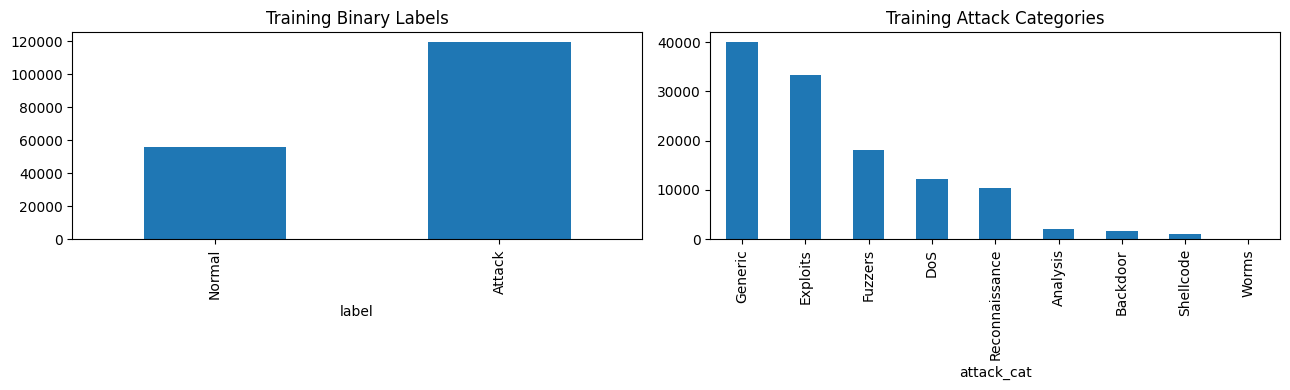

In [10]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
train.label.value_counts().sort_index().rename({0:'Normal',1:'Attack'}).plot.bar(ax=axes[0],title='Training Binary Labels')
train.loc[train.label==1,'attack_cat'].astype(str).value_counts().plot.bar(ax=axes[1],title='Training Attack Categories')
plt.tight_layout();plt.savefig(FIG/'class_attack_distribution.png',dpi=150);plt.show()

## 08 — Leakage and Split Validation

In [11]:
assert len(train)==175341 and len(test)==82332
assert not set(EXCLUDE).intersection(FEATURES)
assert y_train.isin([0,1]).all() and y_test.isin([0,1]).all()
assert X_train.columns.equals(X_test.columns)
print('Fixed UNSW split retained. All target-related columns excluded.')
print('Imputation, encoding, and scaling will be fitted TRAINING-ONLY inside model pipelines.')

Fixed UNSW split retained. All target-related columns excluded.
Imputation, encoding, and scaling will be fitted TRAINING-ONLY inside model pipelines.


## 09 — Save Data Audit and Metadata

In [12]:
meta={'dataset':'UNSW-NB15','training_rows':len(train),'testing_rows':len(test),'features':FEATURES,'categorical_features':CAT,'numeric_features':NUM,'excluded_columns':EXCLUDE,'target':'label','positive_class':'Attack','source':'https://research.unsw.edu.au/projects/unsw-nb15-dataset','seed':SEED}
(OUT/'metadata.json').write_text(json.dumps(meta,indent=2),encoding='utf-8')
(train[['id','attack_cat','label']]).to_csv(OUT/'train_labels_audit.csv',index=False)
(test[['id','attack_cat','label']]).to_csv(OUT/'test_labels_audit.csv',index=False)
print('Saved metadata, quality checks, attack categories and figures to',OUT)

Saved metadata, quality checks, attack categories and figures to /content/drive/MyDrive/CAI470_Project/outputs
